# Who should the bank call? Leakage, regime change and decisions on UCI Bank Marketing

**Ashhar Hussain** · ORCID [0009-0009-1568-9852](https://orcid.org/0009-0009-1568-9852)

A Portuguese bank ran phone campaigns from May 2008 to November 2010 to sell term deposits: 41,188 calls with 20 attributes (Moro et al., 2014). Tutorials on this dataset routinely report a ROC-AUC around 0.93–0.95. Most of that comes from `duration`, the length of the call, which is only known after the call has ended. The rest of the gap between tutorial and reality comes from time: the campaigns span the 2008 financial crisis, interest rates collapse, and the success rate in the last months is ten times that of the first.

**Questions**

1. How much of the headline score is leakage, and how much does a random split flatter the model compared with predicting later calls from earlier ones?
2. Which features survive the regime change? Calendar and macro-economic features are the strongest in-sample signals; are they also the ones that break on the future?
3. Selecting on earlier periods only, which model and feature set should the bank deploy, and how good is it on the final, most shifted period?
4. With probabilities that cannot be trusted after a regime change, how should calls be allocated?

**Protocol.** Rows are in chronological order, so the data are cut into ten consecutive blocks of about 4,100 calls. Model choices are made with rolling-origin evaluation on blocks 7–9 (train on everything before the block, test on the block). Block 10, the last 4,118 calls, is touched once, at the end.

**Run.** Any CPU runtime, about 4 minutes. Data are downloaded from the UCI repository.

In [1]:
import io, json, time, zipfile, warnings, urllib.request
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", message="IProgress not found")
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
import lightgbm as lgb
import optuna

warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
OUT = Path("outputs"); FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
DATA = Path("data"); DATA.mkdir(exist_ok=True)
SEED = 0
rng = np.random.default_rng(SEED)

zpath = DATA / "bank+marketing.zip"
if not zpath.exists():
    urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/222/bank+marketing.zip", zpath)
inner = zipfile.ZipFile(zpath).read("bank-additional.zip")
raw = pd.read_csv(io.BytesIO(zipfile.ZipFile(io.BytesIO(inner)).read("bank-additional/bank-additional-full.csv")), sep=";")
raw["y"] = (raw["y"] == "yes").astype(int)
raw["block"] = np.repeat(np.arange(10), int(np.ceil(len(raw) / 10)))[:len(raw)]  # chronological deciles
print(raw.shape)

(41188, 22)


## 1. Data audit

rows 41,188; exact duplicates 12; success rate 0.113; pdays = 999 (never contacted before) in 96.3% of rows


,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
unknown,330,80,1731,8597,990,990,0,0,0,0,0,0,0,0,0,0,0,0,0,0
distinct,12,4,8,3,3,3,2,10,5,3,78,1544,42,27,8,10,26,26,316,11


,calls,success_rate,euribor_min,euribor_max,months
block,,,,,
0,4119,0.028,4.855,4.860,may
1,4119,0.035,4.856,4.865,"jun,may"
2,4119,0.042,4.864,4.967,"jul,jun"
3,4119,0.066,4.957,4.963,jul
4,4119,0.062,4.961,4.970,"aug,jul"
5,4119,0.055,4.191,5.045,"aug,nov,oct"
6,4119,0.102,1.410,4.191,"apr,dec,mar,nov"
7,4119,0.120,1.299,1.410,"apr,may"
8,4119,0.157,1.029,1.299,"jul,jun,may"


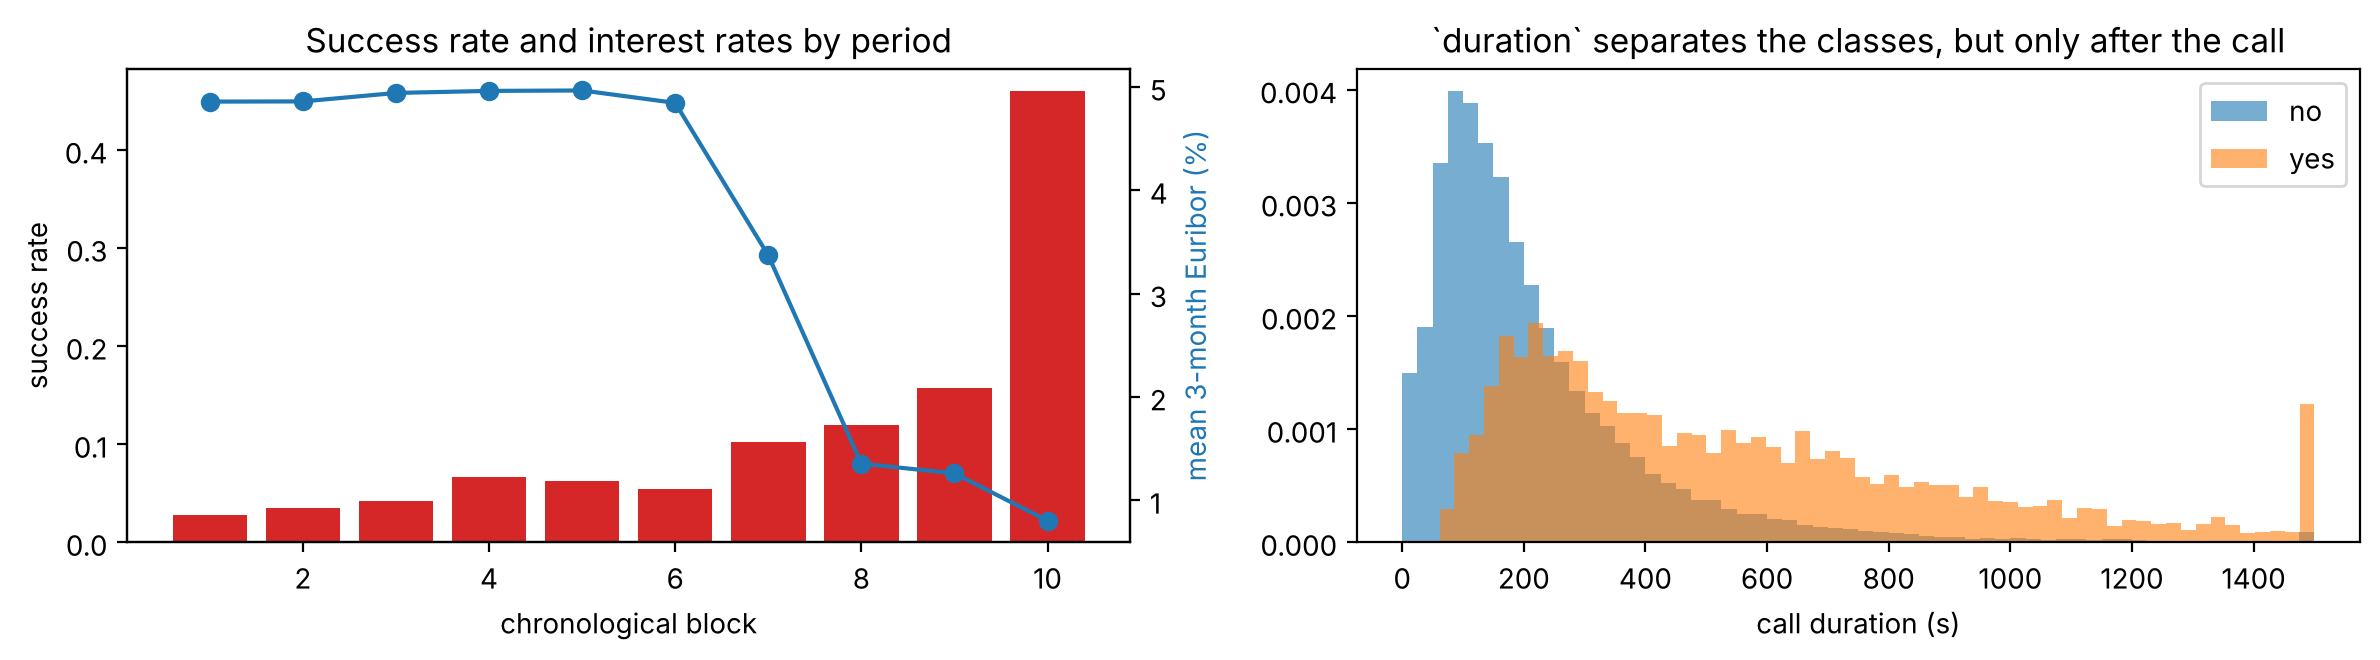

In [2]:
cat_cols = [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c])]
num_cols = [c for c in raw.columns if c not in cat_cols + ["y", "block"]]
audit = pd.DataFrame({
    "unknown": [(raw[c] == "unknown").sum() if c in cat_cols else 0 for c in cat_cols + num_cols],
    "distinct": [raw[c].nunique() for c in cat_cols + num_cols]}, index=cat_cols + num_cols)
print(f"rows {len(raw):,}; exact duplicates {raw.drop(columns='block').duplicated().sum()}; success rate {raw.y.mean():.3f}; "
      f"pdays = 999 (never contacted before) in {(raw.pdays == 999).mean():.1%} of rows")
display(audit.T)

by_block = raw.groupby("block").agg(calls=("y", "size"), success_rate=("y", "mean"), euribor_min=("euribor3m", "min"),
                                    euribor_max=("euribor3m", "max"), months=("month", lambda s: ",".join(sorted(s.unique()))))
display(by_block.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].bar(by_block.index + 1, by_block.success_rate, color="#d62728")
ax2 = ax[0].twinx(); ax2.plot(by_block.index + 1, raw.groupby("block").euribor3m.mean(), "o-", c="#1f77b4")
ax[0].set_xlabel("chronological block"); ax[0].set_ylabel("success rate"); ax2.set_ylabel("mean 3-month Euribor (%)", color="#1f77b4")
ax[0].set_title("Success rate and interest rates by period")
ax[1].hist(raw.duration[raw.y == 0].clip(0, 1500), bins=60, alpha=0.6, density=True, label="no")
ax[1].hist(raw.duration[raw.y == 1].clip(0, 1500), bins=60, alpha=0.6, density=True, label="yes")
ax[1].set_xlabel("call duration (s)"); ax[1].set_title("`duration` separates the classes, but only after the call"); ax[1].legend()
plt.tight_layout(); fig.savefig(FIG / "drift_and_leak.png", dpi=130); plt.show()

The success rate stays between 3% and 7% while the Euribor sits near 5%, then climbs as rates fall, reaching 46% in the last block. The last block also contains months that were rare before. `duration` is a textbook target leak: a call that lasted 0 seconds cannot have been a success.

Preparation: `pdays = 999` is a sentinel, so it becomes a "previously contacted" flag plus the capped number of days; the number of contacts in the campaign is capped at 15.

In [3]:
def prepare(df):
    d = df.copy()
    d["contacted_before"] = (d.pdays != 999).astype(int)
    d["pdays"] = d.pdays.where(d.pdays != 999, 30).clip(upper=30)
    d["campaign"] = d.campaign.clip(upper=15)
    for c in cat_cols:
        d[c] = d[c].astype("category")
    return d


df = prepare(raw)
CALENDAR = ["month", "day_of_week"]
MACRO = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
ALL = [c for c in df.columns if c not in ("y", "block", "duration")]
FEATURE_SETS = {
    "all (no duration)": ALL,
    "no calendar": [c for c in ALL if c not in CALENDAR],
    "no macro": [c for c in ALL if c not in MACRO],
    "client + history only": [c for c in ALL if c not in CALENDAR + MACRO],
}
CATS_ALL = [c for c in ALL if str(df[c].dtype) == "category"]

## 2. Leakage and the split

One LightGBM configuration, fitted with and without `duration`, on a random 80/20 split and on a chronological one (first 80% → last 20%).

In [4]:
PARAMS = dict(objective="binary", learning_rate=0.03, num_leaves=15, min_child_samples=100, feature_fraction=0.8,
              bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, verbose=-1, seed=SEED, num_threads=2)


def fit_gbm(tr, feats, params=PARAMS, rounds=300):
    cats = [c for c in feats if c in CATS_ALL]
    return lgb.train(params, lgb.Dataset(tr[feats], tr.y, categorical_feature=cats), num_boost_round=rounds)


cut = int(0.8 * len(df))
splits = {"random split": train_test_split(df, test_size=len(df) - cut, stratify=df.y, random_state=SEED),
          "chronological split": (df.iloc[:cut], df.iloc[cut:])}
rows = []
for split, (tr, te) in splits.items():
    for feats, name in ((ALL + ["duration"], "with duration (leaky)"), (ALL, "without duration")):
        p = fit_gbm(tr, feats).predict(te[feats])
        rows.append(dict(split=split, features=name, roc_auc=roc_auc_score(te.y, p), pr_auc=average_precision_score(te.y, p)))
leak = pd.DataFrame(rows)
display(leak.pivot(index="features", columns="split", values=["roc_auc", "pr_auc"]).round(3))

roc_auc                           pr_auc  \
split                 chronological split random split chronological split   
features                                                                     
with duration (leaky)               0.815        0.950               0.610   
without duration                    0.680        0.805               0.494   

                                    
split                 random split  
features                            
with duration (leaky)        0.676  
without duration             0.473

## 3. Which features survive the regime change?

Rolling-origin evaluation on blocks 7, 8 and 9: two model families × four feature sets. The logistic regression uses one-hot categories and standardised numbers, with cubic splines for age (linear extrapolation outside the training range). The gradient-boosting model is LightGBM with fixed, moderately regularised settings. PR-AUC is reported next to ROC-AUC because positives are rare and the bank acts on the top of the ranking.

24 fits in 102 s


roc_auc  pr_auc
model               features                              
logistic regression no macro                 0.666   0.242
                    all (no duration)        0.572   0.217
                    client + history only    0.631   0.215
LightGBM            no macro                 0.619   0.205
                    all (no duration)        0.605   0.204
                    no calendar              0.585   0.192
                    client + history only    0.588   0.191
logistic regression no calendar              0.523   0.177

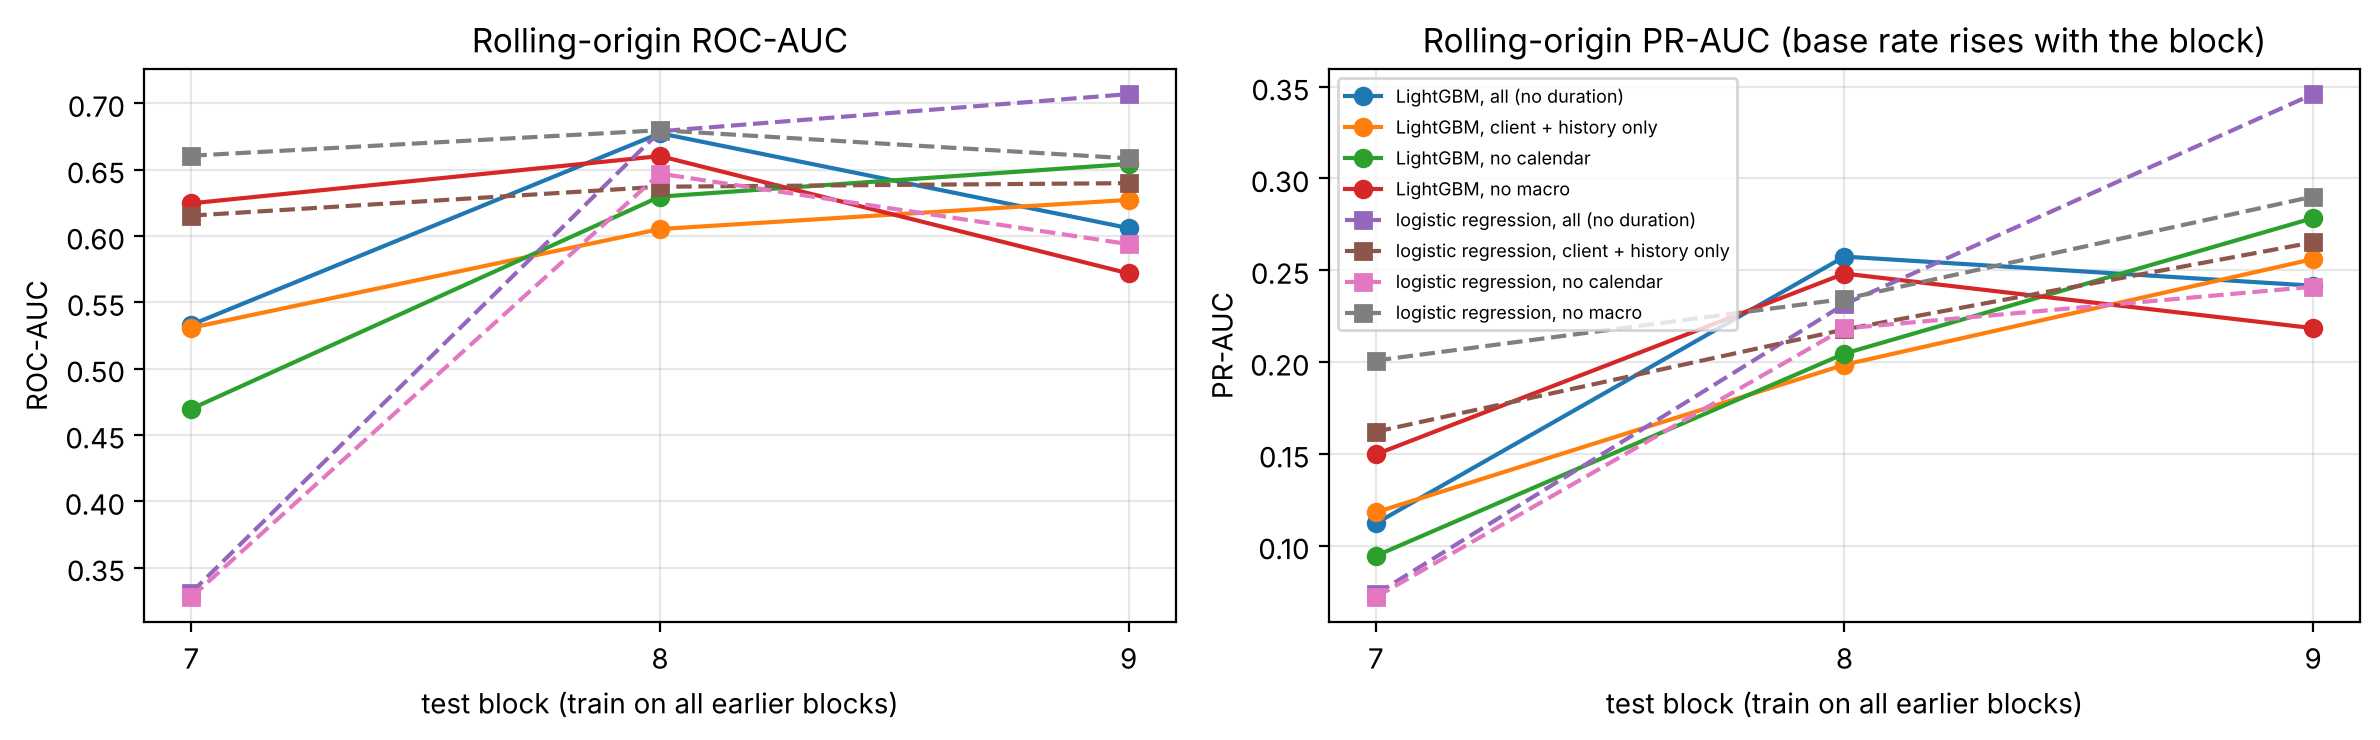

In [5]:
def make_lr(feats, C=0.3):
    cats = [c for c in feats if c in CATS_ALL]
    nums = [c for c in feats if c not in cats]
    spl = [c for c in nums if c == "age"]
    lin = [c for c in nums if c not in spl]
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cats),
                             ("spl", make_pipeline(StandardScaler(), SplineTransformer(n_knots=5, degree=3, extrapolation="linear")), spl),
                             ("lin", StandardScaler(), lin)])
    return make_pipeline(pre, LogisticRegression(C=C, max_iter=5000))


def predict(model_name, tr, te, feats):
    if model_name == "logistic regression":
        return make_lr(feats).fit(tr[feats], tr.y).predict_proba(te[feats])[:, 1]
    return fit_gbm(tr, feats).predict(te[feats])


SEL_BLOCKS = [6, 7, 8]  # zero-based: blocks 7-9
rows = []
t0 = time.time()
for b in SEL_BLOCKS:
    tr, te = df[df.block < b], df[df.block == b]
    for fs, feats in FEATURE_SETS.items():
        for model_name in ("logistic regression", "LightGBM"):
            p = predict(model_name, tr, te, feats)
            rows.append(dict(block=b + 1, features=fs, model=model_name, roc_auc=roc_auc_score(te.y, p),
                             pr_auc=average_precision_score(te.y, p), base_rate=te.y.mean()))
roll = pd.DataFrame(rows)
print(f"{len(rows)} fits in {time.time() - t0:.0f} s")
sel = roll.groupby(["model", "features"])[["roc_auc", "pr_auc"]].mean().sort_values("pr_auc", ascending=False)
display(sel.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
for a, metric in zip(ax, ("roc_auc", "pr_auc")):
    for (model_name, fs), g in roll.groupby(["model", "features"]):
        a.plot(g.block, g[metric], marker="o" if model_name == "LightGBM" else "s",
               ls="-" if model_name == "LightGBM" else "--", label=f"{model_name}, {fs}")
    a.set_xticks([b + 1 for b in SEL_BLOCKS])
    a.set_xlabel("test block (train on all earlier blocks)"); a.set_ylabel(metric.replace("_", "-").upper()); a.grid(alpha=0.3)
ax[0].set_title("Rolling-origin ROC-AUC"); ax[1].set_title("Rolling-origin PR-AUC (base rate rises with the block)")
ax[1].legend(fontsize=6.5, ncol=1, loc="upper left")
plt.tight_layout(); fig.savefig(FIG / "rolling_origin.png", dpi=130); plt.show()

## 4. Model selection on blocks 7–9, then one look at block 10

The best combination on the selection blocks is tuned with Optuna (TPE, 30 trials) using the same rolling-origin protocol, then refitted on blocks 1–9 and evaluated once on block 10. Its strongest rival from the other model family is refitted the same way, and the two are compared with a paired bootstrap on the block-10 calls.

In [6]:
best_model, best_fs = sel.index[0]
rival = sel.reset_index()
rival = rival[rival.model != best_model].iloc[0]
rival_model, rival_fs = rival.model, rival.features
print(f"selected: {best_model} with '{best_fs}'; rival: {rival_model} with '{rival_fs}'")
feats = FEATURE_SETS[best_fs]


def objective(trial):
    if best_model == "LightGBM":
        params = dict(PARAMS, learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
                      num_leaves=trial.suggest_int("num_leaves", 4, 64, log=True),
                      min_child_samples=trial.suggest_int("min_child_samples", 20, 500, log=True),
                      feature_fraction=trial.suggest_float("feature_fraction", 0.4, 1.0),
                      lambda_l2=trial.suggest_float("lambda_l2", 1e-3, 30, log=True))
        rounds = trial.suggest_int("rounds", 100, 800, step=50)
        fit = lambda tr, te: fit_gbm(tr, feats, params, rounds).predict(te[feats])
    else:
        C = trial.suggest_float("C", 1e-3, 10, log=True)
        fit = lambda tr, te: make_lr(feats, C).fit(tr[feats], tr.y).predict_proba(te[feats])[:, 1]
    return float(np.mean([average_precision_score(df[df.block == b].y, fit(df[df.block < b], df[df.block == b])) for b in SEL_BLOCKS]))


t0 = time.time()
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=30)
print(f"tuning: mean selection PR-AUC {study.best_value:.4f} (untuned {sel.iloc[0].pr_auc:.4f}), {time.time() - t0:.0f} s, {study.best_params}")

train, test = df[df.block < 9], df[df.block == 9]
bp = study.best_params
if best_model == "LightGBM":
    params = dict(PARAMS, **{k: v for k, v in bp.items() if k != "rounds"})
    final = fit_gbm(train, feats, params, bp["rounds"])
    p_best = final.predict(test[feats])
else:
    final = make_lr(feats, bp["C"]).fit(train[feats], train.y)
    p_best = final.predict_proba(test[feats])[:, 1]
p_rival = predict(rival_model, train, test, FEATURE_SETS[rival_fs])
p_all = predict("LightGBM", train, test, ALL)  # the 'use every feature' default, for reference

yv = test.y.values
res = pd.DataFrame({f"{best_model}, {best_fs} (selected)": dict(roc_auc=roc_auc_score(yv, p_best), pr_auc=average_precision_score(yv, p_best)),
                    f"{rival_model}, {rival_fs} (rival)": dict(roc_auc=roc_auc_score(yv, p_rival), pr_auc=average_precision_score(yv, p_rival)),
                    "LightGBM, all features (default)": dict(roc_auc=roc_auc_score(yv, p_all), pr_auc=average_precision_score(yv, p_all))}).T
res["base_rate"] = yv.mean()
display(res.round(4))

B = 2000
idx = rng.integers(0, len(test), (B, len(test)))
d_auc = np.array([roc_auc_score(yv[i], p_best[i]) - roc_auc_score(yv[i], p_rival[i]) for i in idx])
d_def = np.array([roc_auc_score(yv[i], p_best[i]) - roc_auc_score(yv[i], p_all[i]) for i in idx])
print(f"selected minus rival, ROC-AUC on block 10: {d_auc.mean():+.4f} [95% CI {np.percentile(d_auc, 2.5):+.4f}, {np.percentile(d_auc, 97.5):+.4f}]")
print(f"selected minus all-feature LightGBM: {d_def.mean():+.4f} [95% CI {np.percentile(d_def, 2.5):+.4f}, {np.percentile(d_def, 97.5):+.4f}]")

selected: logistic regression with 'no macro'; rival: LightGBM with 'no macro'


tuning: mean selection PR-AUC 0.2493 (untuned 0.2418), 24 s, {'C': 0.0010035589880703754}


,roc_auc,pr_auc,base_rate
"logistic regression, no macro (selected)",0.6839,0.6408,0.4596
"LightGBM, no macro (rival)",0.6209,0.5591,0.4596
"LightGBM, all features (default)",0.6379,0.5980,0.4596


selected minus rival, ROC-AUC on block 10: +0.0628 [95% CI +0.0486, +0.0774]
selected minus all-feature LightGBM: +0.0459 [95% CI +0.0343, +0.0575]


## 5. Probabilities after a regime change, and how to allocate calls

A model trained when 7% of calls succeeded will predict low probabilities in a period where 46% succeed, however good its ranking. Two practical options: (a) recalibrate on the most recent labelled block (Platt scaling on block 9, the latest data the bank would have) or (b) stop thresholding probabilities and allocate a fixed calling budget by rank. Both are checked on block 10.

,mean_pred,brier,observed_rate
"selected model, raw",0.1674,0.3084,0.4596
recalibrated on the latest block,0.2623,0.2612,0.4596
constant = true rate (oracle),0.4596,0.2484,0.4596


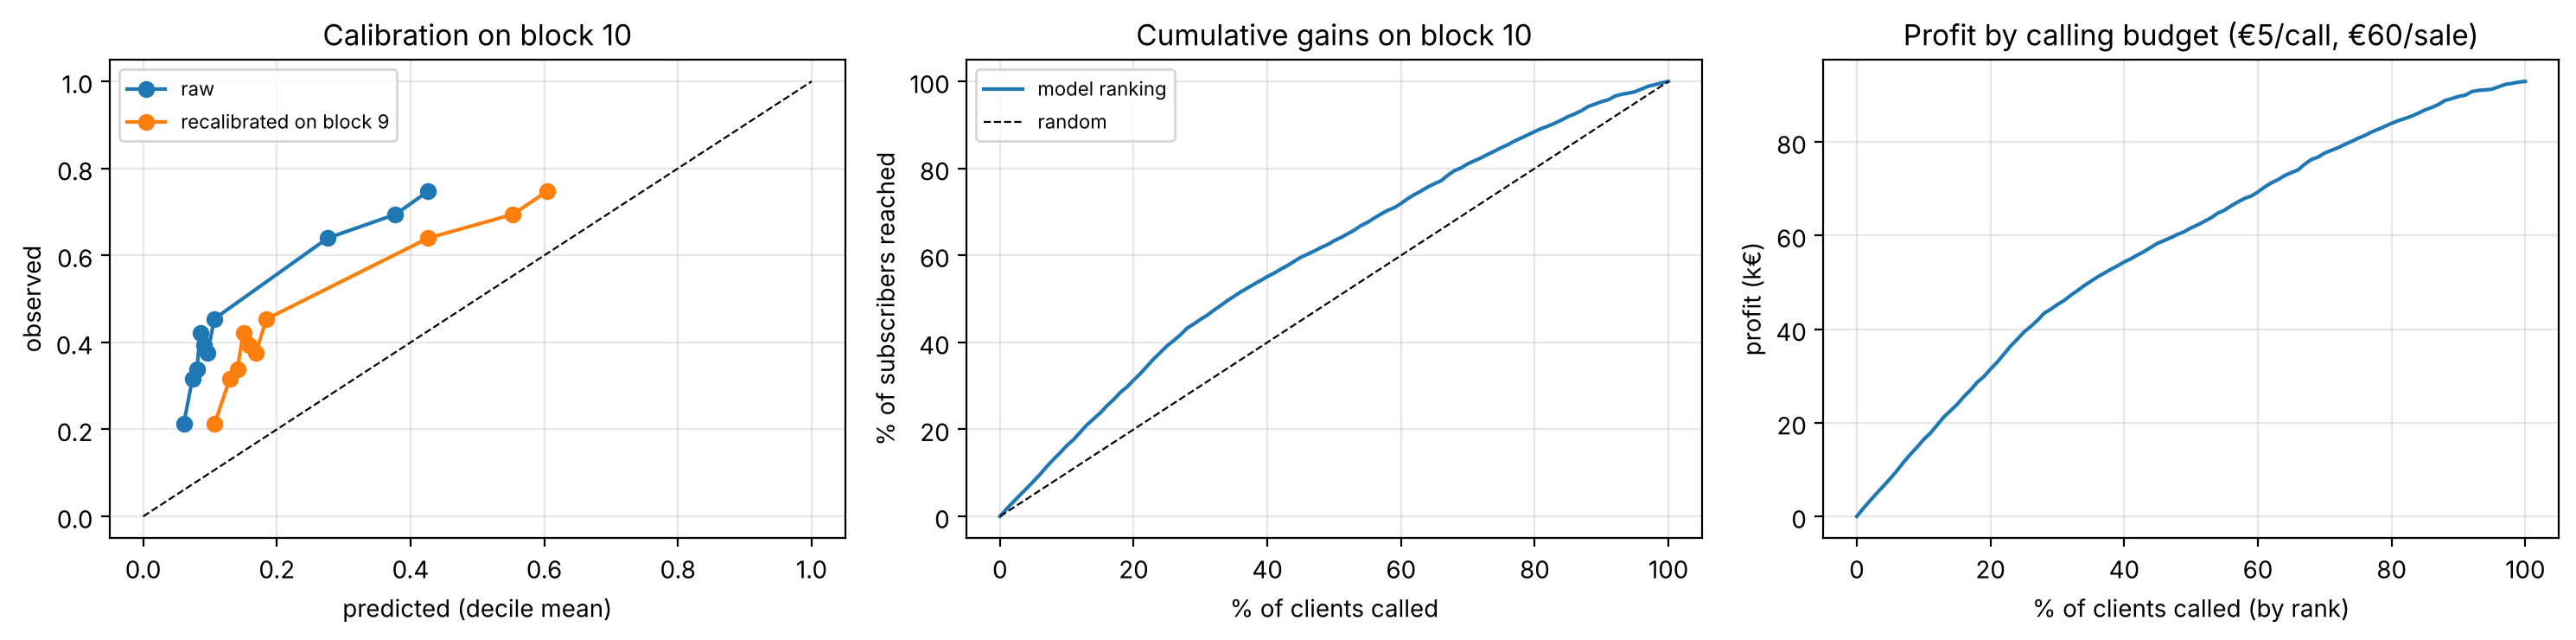

,policy,called,profit
0,threshold p > c/v on raw probabilities,0.693,76875.0
1,threshold on recalibrated probabilities,0.996,92890.0
2,call everyone,1.000,92935.0
3,best budget in hindsight,1.000,92935.0


lift in the top 10/20/30% by score: 10%: 1.63x, 20%: 1.57x, 30%: 1.51x


In [7]:
from sklearn.linear_model import LogisticRegression as _LR
p9 = (final.predict(df[df.block == 8][feats]) if best_model == "LightGBM"
      else final.predict_proba(df[df.block == 8][feats])[:, 1])
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
platt = _LR(C=1e6).fit(logit(p9)[:, None], df[df.block == 8].y)
p_recal = platt.predict_proba(logit(p_best)[:, None])[:, 1]
cal = pd.DataFrame({"selected model, raw": dict(mean_pred=p_best.mean(), brier=brier_score_loss(yv, p_best)),
                    "recalibrated on the latest block": dict(mean_pred=p_recal.mean(), brier=brier_score_loss(yv, p_recal)),
                    "constant = true rate (oracle)": dict(mean_pred=yv.mean(), brier=brier_score_loss(yv, np.full_like(p_best, yv.mean())))}).T
cal["observed_rate"] = yv.mean()
display(cal.round(4))

order = np.argsort(-p_best)
k_grid = np.linspace(0, 1, 101)
gains = np.array([yv[order[:int(k * len(yv))]].sum() / yv.sum() for k in k_grid])
lift = {k: yv[order[:int(k * len(yv))]].mean() / yv.mean() for k in (0.1, 0.2, 0.3)}
COST, VALUE = 5.0, 60.0
profit_k = VALUE * gains * yv.sum() - COST * k_grid * len(yv)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
def reliability(a, p, label):
    q = np.quantile(p, np.linspace(0, 1, 11)); b = np.clip(np.digitize(p, q[1:-1]), 0, 9)
    a.plot([p[b == j].mean() for j in range(10)], [yv[b == j].mean() for j in range(10)], "o-", label=label)
reliability(ax[0], p_best, "raw"); reliability(ax[0], p_recal, "recalibrated on block 9")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set_xlabel("predicted (decile mean)"); ax[0].set_ylabel("observed")
ax[0].set_title("Calibration on block 10"); ax[0].legend(fontsize=8)
ax[1].plot(100 * k_grid, 100 * gains, label="model ranking"); ax[1].plot([0, 100], [0, 100], "k--", lw=0.8, label="random")
ax[1].set_xlabel("% of clients called"); ax[1].set_ylabel("% of subscribers reached"); ax[1].set_title("Cumulative gains on block 10"); ax[1].legend(fontsize=8)
ax[2].plot(100 * k_grid, profit_k / 1000); ax[2].set_xlabel("% of clients called (by rank)"); ax[2].set_ylabel("profit (k€)")
ax[2].set_title(f"Profit by calling budget (€{COST:g}/call, €{VALUE:g}/sale)")
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); fig.savefig(FIG / "calibration_gains_profit.png", dpi=130); plt.show()

thr_raw, thr_recal = p_best > COST / VALUE, p_recal > COST / VALUE
pol = pd.DataFrame([
    dict(policy="threshold p > c/v on raw probabilities", called=thr_raw.mean(), profit=VALUE * yv[thr_raw].sum() - COST * thr_raw.sum()),
    dict(policy="threshold on recalibrated probabilities", called=thr_recal.mean(), profit=VALUE * yv[thr_recal].sum() - COST * thr_recal.sum()),
    dict(policy="call everyone", called=1.0, profit=VALUE * yv.sum() - COST * len(yv)),
    dict(policy="best budget in hindsight", called=k_grid[profit_k.argmax()], profit=profit_k.max())])
display(pol.round(3))
print("lift in the top 10/20/30% by score: " + ", ".join(f"{100 * k:.0f}%: {v:.2f}x" for k, v in lift.items()))

## 6. What drives the selected model, and where it is weaker

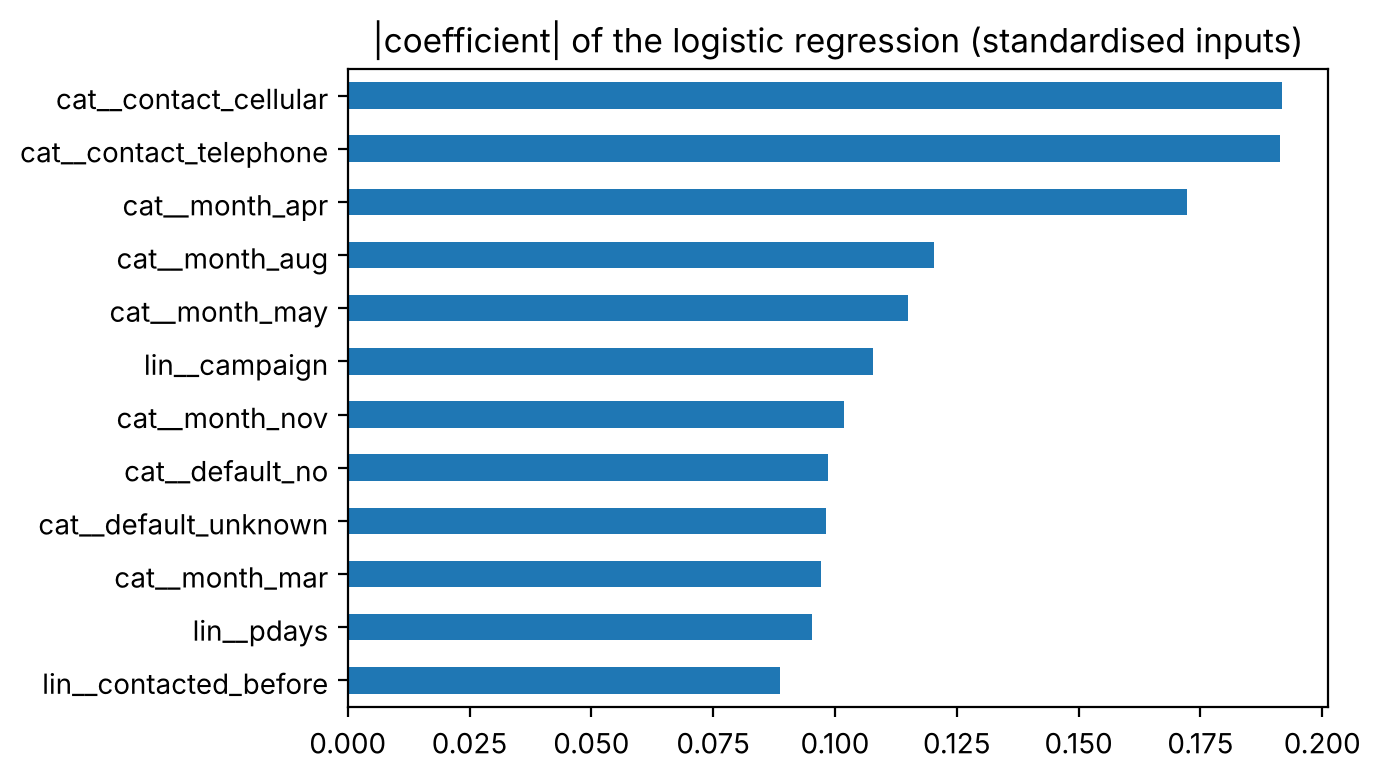

,segment,n,success_rate,roc_auc
0,age_band = <25,373,0.475,0.706
1,age_band = 25-34,1396,0.440,0.677
2,age_band = 35-49,1043,0.465,0.693
3,age_band = 50-59,582,0.462,0.711
4,age_band = 60+,723,0.480,0.659
5,contact = cellular,3493,0.491,0.656
6,contact = telephone,624,0.284,0.671
7,poutcome = failure,1067,0.343,0.578
8,poutcome = nonexistent,2012,0.383,0.598
9,poutcome = success,1038,0.727,0.523


In [8]:
if best_model == "LightGBM":
    contrib = final.predict(test[feats], pred_contrib=True)[:, :-1]
    imp = pd.Series(np.abs(contrib).mean(0), index=feats).sort_values()
    imp_title = "Mean |SHAP| on block 10 (log-odds, TreeSHAP)"
else:
    lr_est = final[-1]; names = final[0].get_feature_names_out()
    imp = pd.Series(np.abs(lr_est.coef_[0]), index=names).sort_values()
    imp_title = "|coefficient| of the logistic regression (standardised inputs)"
fig, ax = plt.subplots(figsize=(7, 4))
imp.tail(12).plot.barh(ax=ax, color="#1f77b4"); ax.set_title(imp_title)
plt.tight_layout(); fig.savefig(FIG / "importance.png", dpi=130); plt.show()

seg = test.assign(p=p_best, age_band=pd.cut(test.age, [0, 25, 35, 50, 60, 100], labels=["<25", "25-34", "35-49", "50-59", "60+"]))
rows = []
for col in ("age_band", "contact", "poutcome"):
    for lvl, g in seg.groupby(col, observed=True):
        if g.y.nunique() == 2 and len(g) >= 100:
            rows.append(dict(segment=f"{col} = {lvl}", n=len(g), success_rate=g.y.mean(), roc_auc=roc_auc_score(g.y, g.p)))
display(pd.DataFrame(rows).round(3))

## Findings

In [9]:
from IPython.display import Markdown
lk = leak.set_index(["split", "features"])
s = sel.reset_index()
md = "\n\n".join([
    f"**Leakage and split.** With `duration`, LightGBM scores ROC-AUC {lk.loc[('random split', 'with duration (leaky)'), 'roc_auc']:.3f} on a random split. "
    f"Without it, {lk.loc[('random split', 'without duration'), 'roc_auc']:.3f} on a random split and {lk.loc[('chronological split', 'without duration'), 'roc_auc']:.3f} "
    f"when the last 20% of calls are predicted from the first 80%.",
    f"**Feature sets.** Mean rolling-origin PR-AUC on blocks 7–9: " + "; ".join(
        f"{r.model} / {r.features} {r.pr_auc:.3f}" for r in s.itertuples()) + ".",
    f"**Selected model on the untouched final block.** {best_model} with '{best_fs}' (tuned on blocks 7–9): ROC-AUC {res.iloc[0].roc_auc:.3f}, "
    f"PR-AUC {res.iloc[0].pr_auc:.3f} at a base rate of {yv.mean():.3f}; against {rival_model} with '{rival_fs}' the ROC-AUC difference is "
    f"{d_auc.mean():+.3f} [{np.percentile(d_auc, 2.5):+.3f}, {np.percentile(d_auc, 97.5):+.3f}], and against LightGBM with every feature "
    f"{d_def.mean():+.3f} [{np.percentile(d_def, 2.5):+.3f}, {np.percentile(d_def, 97.5):+.3f}].",
    f"**Decisions.** Raw probabilities averaged {p_best.mean():.3f} against an observed rate of {yv.mean():.3f}; recalibrating on the latest block moved the mean to "
    f"{p_recal.mean():.3f}. The ranking held up better: the top 20% of clients by score subscribe at {lift[0.2]:.2f}× the average rate, and at €{COST:g} per call "
    f"and €{VALUE:g} per sale the best calling budget in this period was {100 * k_grid[profit_k.argmax()]:.0f}% of clients.",
])
(OUT / "findings.md").write_text(md)
json.dump(dict(leakage=leak.to_dict("records"), rolling=roll.to_dict("records"), selected=[best_model, best_fs],
               final=res.reset_index().to_dict("records"), auc_diff_vs_rival=[float(d_auc.mean()), float(np.percentile(d_auc, 2.5)), float(np.percentile(d_auc, 97.5))],
               calibration=cal.reset_index().to_dict("records"), policies=pol.to_dict("records"), lift={str(k): float(v) for k, v in lift.items()}),
          open(OUT / "summary.json", "w"), indent=2)
display(Markdown(md))

**Leakage and split.** With `duration`, LightGBM scores ROC-AUC 0.950 on a random split. Without it, 0.805 on a random split and 0.680 when the last 20% of calls are predicted from the first 80%.

**Feature sets.** Mean rolling-origin PR-AUC on blocks 7–9: logistic regression / no macro 0.242; logistic regression / all (no duration) 0.217; logistic regression / client + history only 0.215; LightGBM / no macro 0.205; LightGBM / all (no duration) 0.204; LightGBM / no calendar 0.192; LightGBM / client + history only 0.191; logistic regression / no calendar 0.177.

**Selected model on the untouched final block.** logistic regression with 'no macro' (tuned on blocks 7–9): ROC-AUC 0.684, PR-AUC 0.641 at a base rate of 0.460; against LightGBM with 'no macro' the ROC-AUC difference is +0.063 [+0.049, +0.077], and against LightGBM with every feature +0.046 [+0.034, +0.057].

**Decisions.** Raw probabilities averaged 0.167 against an observed rate of 0.460; recalibrating on the latest block moved the mean to 0.262. The ranking held up better: the top 20% of clients by score subscribe at 1.57× the average rate, and at €5 per call and €60 per sale the best calling budget in this period was 100% of clients.

### Limitations

* The rows are ordered by time but carry no dates, so blocks are by position.
* Costs and values are assumptions; only the shape of the profit curve should be read, not the euro amounts.
* No causal claim: the model predicts who subscribes when called, not who subscribes *because* they were called; that needs uplift modelling and a control group.
* Block 10 is a single period with an unusual success rate, so its numbers carry wide uncertainty; the bootstrap intervals above cover resampling of calls, not of periods.

### References

Moro, Cortez & Rita (2014) *A data-driven approach to predict the success of bank telemarketing*, Decision Support Systems 62 · Kaufman et al. (2012) *Leakage in data mining*, ACM TKDD · Tashman (2000) *Out-of-sample tests of forecasting accuracy*, International Journal of Forecasting · Ke et al. (2017) *LightGBM* · Akiba et al. (2019) *Optuna* · Platt (1999) *Probabilistic outputs for support vector machines*